# Clustering of Iris dataset using KMeans & Agglomerative Algorithms

## **Import libraries**

In [359]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans,AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage
from sklearn.datasets import load_iris

## **Load data**

In [360]:
iris=load_iris(as_frame=True)
df=pd.DataFrame(iris.data)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# Information from data

In [361]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [362]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0


In [363]:
df.duplicated().sum()

np.int64(1)

In [364]:
df.drop_duplicates(inplace=True)

In [365]:
df.duplicated().sum()

np.int64(0)

# Outlier detection and removal

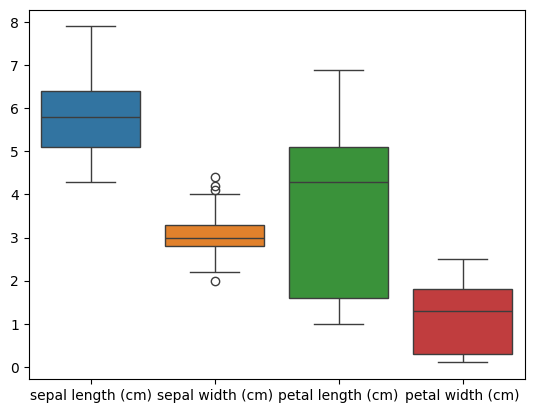

In [366]:
sns.boxplot(df)
plt.show()

In [367]:
q1=df['sepal width (cm)'].quantile(0.25)
q3=df['sepal width (cm)'].quantile(0.75)
iqr=q3-q1
lower_bound=q1-(1.5*iqr)
upper_bound=q3+(1.5*iqr)
df_iqr_removed=df[~((df['sepal width (cm)']<lower_bound)|(df['sepal width (cm)']>upper_bound))]

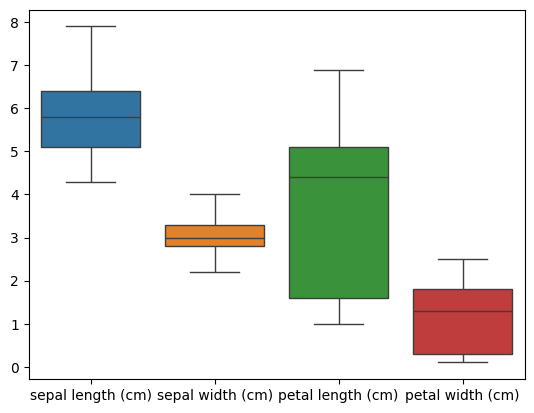

In [368]:
sns.boxplot(df_iqr_removed)
plt.show()

# Handling skewness

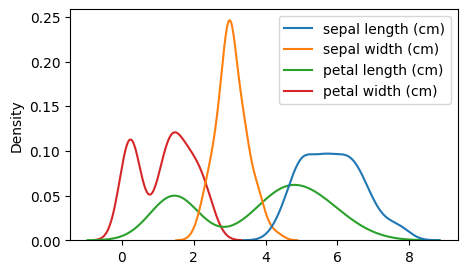

In [369]:
plt.figure(figsize=(5,3))
sns.kdeplot(df)
plt.show()

In [370]:
skew_corrected_df=np.log(df)
skew_corrected_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,1.629241,1.252763,0.336472,-1.609438
1,1.589235,1.098612,0.336472,-1.609438
2,1.547563,1.163151,0.262364,-1.609438
3,1.526056,1.131402,0.405465,-1.609438
4,1.609438,1.280934,0.336472,-1.609438


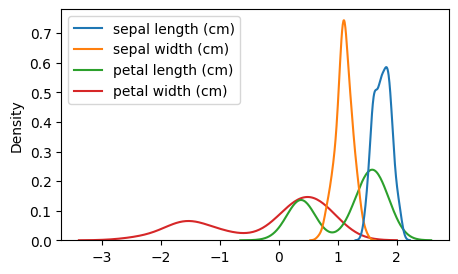

In [371]:
plt.figure(figsize=(5,3))
sns.kdeplot(skew_corrected_df)
plt.show()

# Feature Scaling

In [372]:
scaler=StandardScaler()
scaled_df=scaler.fit_transform(skew_corrected_df)
scaled_df=pd.DataFrame(skew_corrected_df,columns=df.columns)


# Elbow method for finding K

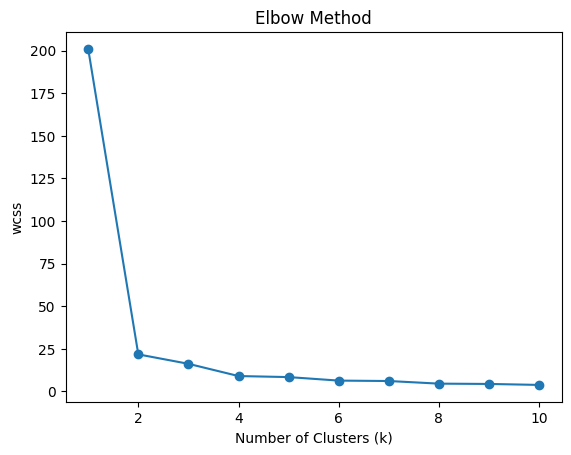

In [373]:
wcss=[]
for k in range(1,11):

  kmodel=KMeans(n_clusters=k,random_state=42)
  kmodel.fit(scaled_df)
  wcss.append(kmodel.inertia_)

plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('wcss')
plt.title('Elbow Method')
plt.show()

# KMeans Alogorithm

In [383]:
k_model=KMeans(n_clusters=2,random_state=42)
k_model.fit(scaled_df)

KMeans(n_clusters=2, random_state=42)

In [385]:
cluster=k_model.predict(scaled_df)
df["cluster"]=cluster
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster,H_cluster
0,5.1,3.5,1.4,0.2,1,1
1,4.9,3.0,1.4,0.2,1,1
2,4.7,3.2,1.3,0.2,1,1
3,4.6,3.1,1.5,0.2,1,1
4,5.0,3.6,1.4,0.2,1,1
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0,0
146,6.3,2.5,5.0,1.9,0,0
147,6.5,3.0,5.2,2.0,0,0
148,6.2,3.4,5.4,2.3,0,0


In [386]:
df['cluster'].value_counts()

,count
cluster,
0,99
1,50


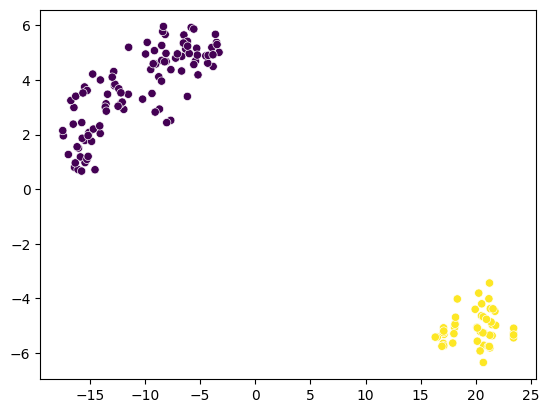

In [387]:
tsne=TSNE(n_components=2,
          perplexity=30,
          learning_rate=200,
          random_state=42)
tsne_df=tsne.fit_transform(scaled_df)
sns.scatterplot(x=tsne_df[:,0],
                y=tsne_df[:,1],
                c=df['cluster'])
plt.show()


Kmeans is an unsupervised learning algorithm that divides data into a specific number of clusters called K.

*   Working
1.   Choose K
2.   Randomly place K centriods in the data point
3.   Each point is assigned to nearest centriod
4.   Update centriod
5.   Repeat until centroids stop moving


*   Why suit :
1. The dataset contains numerical measurements.
2. Flowers with similar measurements can be grouped together.
3. We can specify number of clusters
4. KMeans is simple to implement and visualize














# Dendrogram

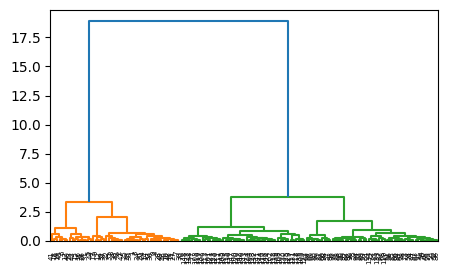

In [388]:
plt.figure(figsize=(5,3))
linkage_df=linkage(scaled_df,method="ward")
dendrogram(linkage_df)
plt.show()



# Agglomerative Algorithm

In [389]:
hmodel=AgglomerativeClustering(n_clusters=2,
                               metric="euclidean",
                               linkage="ward")
hmodel.fit(scaled_df)

AgglomerativeClustering()

In [390]:
h_prediced_cluster=hmodel.fit_predict(scaled_df)

In [391]:
df["H_cluster"]=h_prediced_cluster
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster,H_cluster
0,5.1,3.5,1.4,0.2,1,1
1,4.9,3.0,1.4,0.2,1,1
2,4.7,3.2,1.3,0.2,1,1
3,4.6,3.1,1.5,0.2,1,1
4,5.0,3.6,1.4,0.2,1,1
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0,0
146,6.3,2.5,5.0,1.9,0,0
147,6.5,3.0,5.2,2.0,0,0
148,6.2,3.4,5.4,2.3,0,0


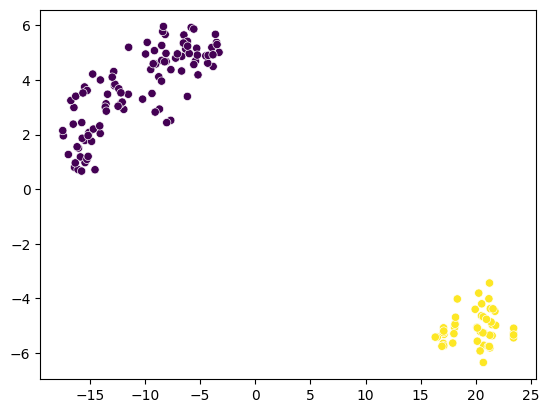

In [392]:
tsne_h=TSNE(n_components=2,
          perplexity=30,
          learning_rate=200,
          random_state=42)
tsne_df=tsne.fit_transform(scaled_df)
sns.scatterplot(x=tsne_df[:,0],
                y=tsne_df[:,1],
                c=df['H_cluster'])
plt.show()


Hierarchical clustering  is an unsupervised learning algorithm that build a tree like hierarchy of clusters.Agglomerative is a type of hierarchical clustering which is commenly used.

*   Working
1.  Start with N cluster
2.  Compute distance matrix
3.  Merge the closest clusters
4.  Update distance
5.  Repeat until one culster remains


*   Why suit :
1. It can group flowers using their measurement similarities.
2. Its hierarchical structure can also be visualized using a dendrogram.













